In [1]:
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import pandas as pd

# Definir las variables de entrada y salida difusas
creencia = ctrl.Antecedent(np.arange(0, 1.01, 0.01), 'creencia')
plausibilidad = ctrl.Antecedent(np.arange(0, 1.01, 0.01), 'plausibilidad')
probabilidad_pignistica = ctrl.Antecedent(np.arange(0, 1.01, 0.01), 'probabilidad_pignistica')

riesgo_discrepancia = ctrl.Consequent(np.arange(0, 11, 1), 'riesgo_discrepancia')
impacto_potencial = ctrl.Consequent(np.arange(0, 11, 1), 'impacto_potencial')
probabilidad_ocurrencia = ctrl.Consequent(np.arange(0, 11, 1), 'probabilidad_ocurrencia')

# Definir las funciones de membresía para cada variable
creencia.automf(3)
plausibilidad.automf(3)
probabilidad_pignistica.automf(3)

riesgo_discrepancia.automf(3)
impacto_potencial.automf(3)
probabilidad_ocurrencia.automf(3)





e:\fusion_datos\taller final\venv\lib\site-packages\skfuzzy\control\fuzzyvariable.py:122: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


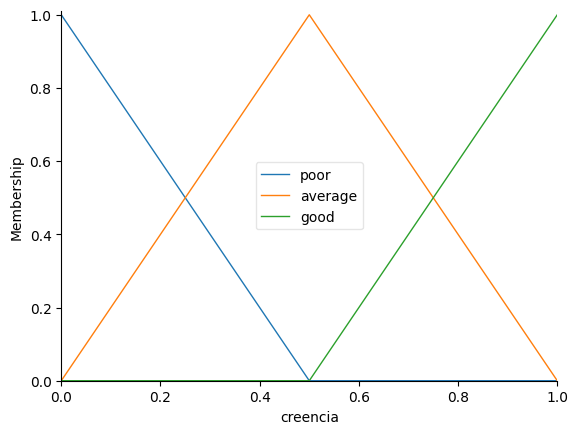

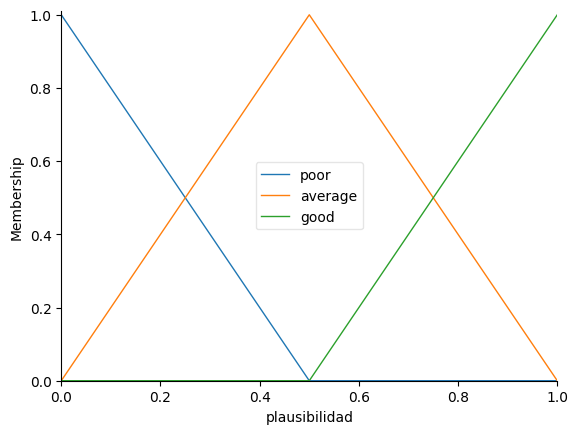

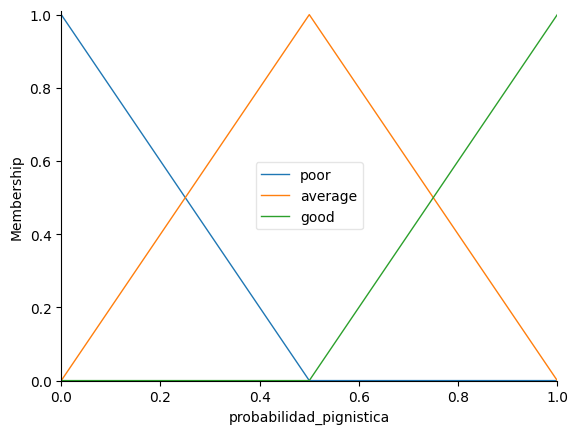

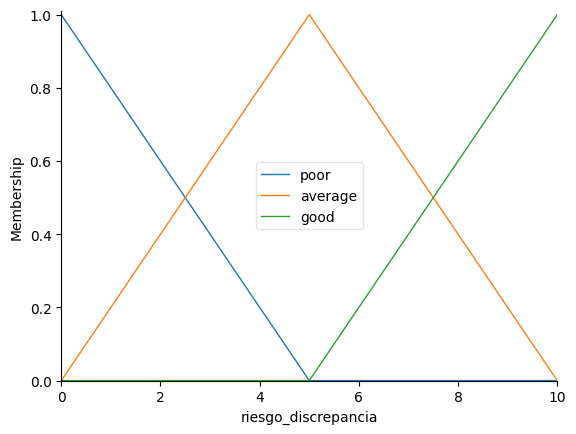

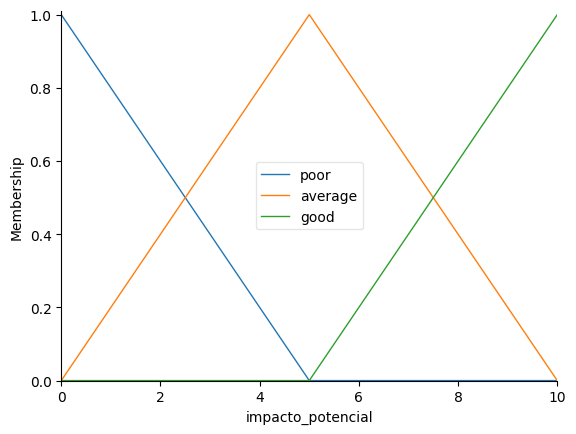

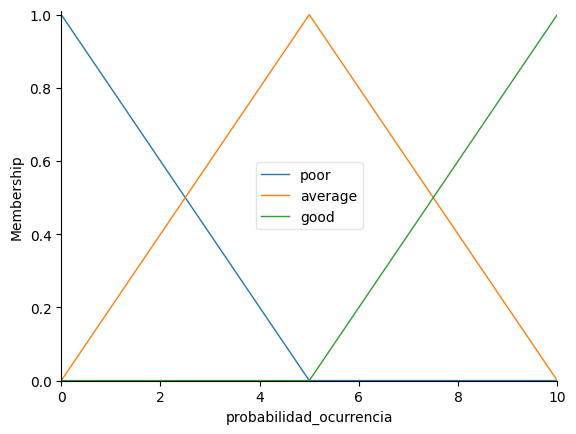

In [3]:
creencia.view()
plausibilidad.view()
probabilidad_pignistica.view()

riesgo_discrepancia.view()
impacto_potencial.view()
probabilidad_ocurrencia.view()

In [6]:
# Crear las reglas difusas para el Nivel 3
rules = []

# Reglas para Riesgo de Discrepancia
rules.append(ctrl.Rule(creencia['good'] & plausibilidad['good'] & probabilidad_pignistica['good'], 
                       riesgo_discrepancia['poor']))
rules.append(ctrl.Rule(creencia['poor'] & plausibilidad['poor'] & probabilidad_pignistica['poor'], 
                       riesgo_discrepancia['good']))
rules.append(ctrl.Rule(creencia['average'] & plausibilidad['average'] & probabilidad_pignistica['average'], 
                       riesgo_discrepancia['average']))
rules.append(ctrl.Rule(creencia['good'] & plausibilidad['average'] & probabilidad_pignistica['poor'], 
                       riesgo_discrepancia['average']))
rules.append(ctrl.Rule(creencia['poor'] & plausibilidad['good'] & probabilidad_pignistica['average'], 
                       riesgo_discrepancia['good']))
rules.append(ctrl.Rule(creencia['average'] & plausibilidad['poor'] & probabilidad_pignistica['good'], 
                       riesgo_discrepancia['average']))

# Reglas para Impacto Potencial
rules.append(ctrl.Rule(creencia['good'] & plausibilidad['good'] & probabilidad_pignistica['good'], 
                       impacto_potencial['good']))
rules.append(ctrl.Rule(creencia['poor'] & plausibilidad['poor'] & probabilidad_pignistica['poor'], 
                       impacto_potencial['poor']))
rules.append(ctrl.Rule(creencia['average'] & plausibilidad['average'] & probabilidad_pignistica['average'], 
                       impacto_potencial['average']))
rules.append(ctrl.Rule(creencia['good'] & plausibilidad['average'] & probabilidad_pignistica['poor'], 
                       impacto_potencial['good']))
rules.append(ctrl.Rule(creencia['poor'] & plausibilidad['good'] & probabilidad_pignistica['average'], 
                       impacto_potencial['average']))
rules.append(ctrl.Rule(creencia['average'] & plausibilidad['poor'] & probabilidad_pignistica['good'], 
                       impacto_potencial['poor']))

# Reglas para Probabilidad de Ocurrencia
rules.append(ctrl.Rule(creencia['good'] & plausibilidad['good'] & probabilidad_pignistica['good'], 
                       probabilidad_ocurrencia['good']))
rules.append(ctrl.Rule(creencia['poor'] & plausibilidad['poor'] & probabilidad_pignistica['poor'], 
                       probabilidad_ocurrencia['poor']))
rules.append(ctrl.Rule(creencia['average'] & plausibilidad['average'] & probabilidad_pignistica['average'], 
                       probabilidad_ocurrencia['average']))
rules.append(ctrl.Rule(creencia['good'] & plausibilidad['average'] & probabilidad_pignistica['poor'], 
                       probabilidad_ocurrencia['poor']))
rules.append(ctrl.Rule(creencia['poor'] & plausibilidad['good'] & probabilidad_pignistica['average'], 
                       probabilidad_ocurrencia['average']))
rules.append(ctrl.Rule(creencia['average'] & plausibilidad['poor'] & probabilidad_pignistica['good'], 
                       probabilidad_ocurrencia['good']))

In [8]:
# Crear las reglas difusas para el Nivel 3
rules = []

for creencia_level in ['poor', 'average', 'good']:
    for plausibilidad_level in ['poor', 'average', 'good']:
        for probabilidad_pignistica_level in ['poor', 'average', 'good']:
            if creencia_level == 'good' or plausibilidad_level == 'good' or probabilidad_pignistica_level == 'good':
                riesgo_output = 'good'
                impacto_output = 'good'
                probabilidad_output = 'good'
            elif plausibilidad_level == 'poor' and (creencia_level == 'average' or probabilidad_pignistica_level == 'average'):
                riesgo_output = 'good'
                impacto_output = 'good'
                probabilidad_output = 'good'
            elif creencia_level == 'poor' and plausibilidad_level == 'poor' and probabilidad_pignistica_level != 'good':
                riesgo_output = 'poor'
                impacto_output = 'poor'
                probabilidad_output = 'poor'
            else:
                riesgo_output = 'average'
                impacto_output = 'average'
                probabilidad_output = 'average'
            
            # Crear y añadir la regla
            rule_riesgo = ctrl.Rule(creencia[creencia_level] & plausibilidad[plausibilidad_level] & probabilidad_pignistica[probabilidad_pignistica_level], riesgo_discrepancia[riesgo_output])
            rule_impacto = ctrl.Rule(creencia[creencia_level] & plausibilidad[plausibilidad_level] & probabilidad_pignistica[probabilidad_pignistica_level], impacto_potencial[impacto_output])
            rule_probabilidad = ctrl.Rule(creencia[creencia_level] & plausibilidad[plausibilidad_level] & probabilidad_pignistica[probabilidad_pignistica_level], probabilidad_ocurrencia[probabilidad_output])
            rules.extend([rule_riesgo, rule_impacto, rule_probabilidad])

In [7]:
cont=0
for rule in rules:
    cont+=1
    print(rule)
print(cont)

IF (creencia[good] AND plausibilidad[good]) AND probabilidad_pignistica[good] THEN riesgo_discrepancia[poor]
	AND aggregation function : fmin
	OR aggregation function  : fmax
IF (creencia[poor] AND plausibilidad[poor]) AND probabilidad_pignistica[poor] THEN riesgo_discrepancia[good]
	AND aggregation function : fmin
	OR aggregation function  : fmax
IF (creencia[average] AND plausibilidad[average]) AND probabilidad_pignistica[average] THEN riesgo_discrepancia[average]
	AND aggregation function : fmin
	OR aggregation function  : fmax
IF (creencia[good] AND plausibilidad[average]) AND probabilidad_pignistica[poor] THEN riesgo_discrepancia[average]
	AND aggregation function : fmin
	OR aggregation function  : fmax
IF (creencia[poor] AND plausibilidad[good]) AND probabilidad_pignistica[average] THEN riesgo_discrepancia[good]
	AND aggregation function : fmin
	OR aggregation function  : fmax
IF (creencia[average] AND plausibilidad[poor]) AND probabilidad_pignistica[good] THEN riesgo_discrepanci

In [8]:
# Crear el sistema de control difuso
control_system = ctrl.ControlSystem(rules)
riesgo = ctrl.ControlSystemSimulation(control_system)

In [9]:
riesgo.input['creencia'] = 0.2
riesgo.input['plausibilidad'] = 0.1
riesgo.input['probabilidad_pignistica'] = 0.8

# Calcular el riesgo
riesgo.compute()

print(f"Riesgo Discrepancia: {riesgo.output['riesgo_discrepancia']}")
print(f"Impacto Potencial: {riesgo.output['impacto_potencial']}")
print(f"Probabilidad Ocurrencia: {riesgo.output['probabilidad_ocurrencia']}")

Riesgo Discrepancia: 5.0
Impacto Potencial: 3.948717948717948
Probabilidad Ocurrencia: 6.051282051282053


In [10]:
import pandas as pd

# Cargar los resultados del Nivel 2
resultados_nivel2 = pd.read_csv('resultados_dempster_shafer.csv')

# Asegúrate de que las columnas estén correctamente definidas
creencias = ['Creencia_Baja', 'Creencia_Media', 'Creencia_Alta']
plausibilidades = ['Plausibilidad_Baja', 'Plausibilidad_Media', 'Plausibilidad_Alta']
probabilidades_pignisticas = ['Probabilidad_Pignistica_Baja', 'Probabilidad_Pignistica_Media', 'Probabilidad_Pignistica_Alta']

# Inicializar las listas para almacenar las salidas del FIS
riesgo_discrepancias = []
impactos_potenciales = []
probabilidades_ocurrencias = []

# Inicializar y configurar el sistema de inferencia difusa (FIS) `riesgo`
# Este paso es crítico y debe ajustarse a tu configuración específica de FIS
# Aquí, se asume que el FIS ya está configurado adecuadamente

# Aplicar el FIS a cada conjunto de predicciones
for i in range(len(resultados_nivel2)):
    creencia = max(resultados_nivel2.loc[i, creencias])
    plausibilidad = max(resultados_nivel2.loc[i, plausibilidades])
    probabilidad_pignistica = max(resultados_nivel2.loc[i, probabilidades_pignisticas])
    
    riesgo.input['creencia'] = creencia
    riesgo.input['plausibilidad'] = plausibilidad
    riesgo.input['probabilidad_pignistica'] = probabilidad_pignistica
    
    # Calcular la valoración de la situación
    riesgo.compute()
    
    # Almacenar la valoración
    riesgo_discrepancias.append(riesgo.output['riesgo_discrepancia'])
    impactos_potenciales.append(riesgo.output['impacto_potencial'])
    probabilidades_ocurrencias.append(riesgo.output['probabilidad_ocurrencia'])

# Guardar las valoraciones en un archivo CSV
salidas_fis = pd.DataFrame({
    'Riesgo_Discrepancia': riesgo_discrepancias,
    'Impacto_Potencial': impactos_potenciales,
    'Probabilidad_Ocurrencia': probabilidades_ocurrencias
})
salidas_fis.to_csv('salidas_fis.csv', index=False)

print("Salidas del FIS guardadas en 'salidas_fis.csv'")


Salidas del FIS guardadas en 'salidas_fis.csv'


In [17]:
salidas_fis.describe()

,Riesgo_Discrepancia,Impacto_Potencial,Probabilidad_Ocurrencia
count,1.000000,1.000000,1.000000
mean,1.666667,8.333333,8.333333
std,NaN,NaN,NaN
min,1.666667,8.333333,8.333333
25%,1.666667,8.333333,8.333333
50%,1.666667,8.333333,8.333333
75%,1.666667,8.333333,8.333333
max,1.666667,8.333333,8.333333


In [18]:
import pandas as pd
from pyds import MassFunction

# Cargar las salidas del FIS
salidas_fis = pd.read_csv('salidas_fis.csv')

# Definir las funciones de masa iniciales
mass_functions_riesgo = []
mass_functions_impacto = []
mass_functions_probabilidad = []

# Crear las funciones de masa según los valores del CSV
for i in range(len(salidas_fis)):
    riesgo_discrepancia = salidas_fis['Riesgo_Discrepancia'][i]
    impacto_potencial = salidas_fis['Impacto_Potencial'][i]
    probabilidad_ocurrencia = salidas_fis['Probabilidad_Ocurrencia'][i]
    
    mass_function_riesgo = MassFunction({frozenset(['bajo']): 1.0}) if riesgo_discrepancia <= 3.33 else MassFunction({frozenset(['medio']): 1.0}) if riesgo_discrepancia <= 6.66 else MassFunction({frozenset(['alto']): 1.0})
    mass_function_impacto = MassFunction({frozenset(['bajo']): 1.0}) if impacto_potencial <= 3.33 else MassFunction({frozenset(['medio']): 1.0}) if impacto_potencial <= 6.66 else MassFunction({frozenset(['alto']): 1.0})
    mass_function_probabilidad = MassFunction({frozenset(['bajo']): 1.0}) if probabilidad_ocurrencia <= 3.33 else MassFunction({frozenset(['medio']): 1.0}) if probabilidad_ocurrencia <= 6.66 else MassFunction({frozenset(['alto']): 1.0})
    
    mass_functions_riesgo.append(mass_function_riesgo)
    mass_functions_impacto.append(mass_function_impacto)
    mass_functions_probabilidad.append(mass_function_probabilidad)

# Combinar las funciones de masa utilizando la regla de combinación de Dempster para cada conjunto de salidas
riesgo_final = mass_functions_riesgo[0]
impacto_final = mass_functions_impacto[0]
probabilidad_final = mass_functions_probabilidad[0]

for mass_function_riesgo, mass_function_impacto, mass_function_probabilidad in zip(mass_functions_riesgo[1:], mass_functions_impacto[1:], mass_functions_probabilidad[1:]):
    riesgo_final = riesgo_final & mass_function_riesgo
    impacto_final = impacto_final & mass_function_impacto
    probabilidad_final = probabilidad_final & mass_function_probabilidad

# Obtener la creencia, plausibilidad y probabilidad pignística de la valoración final
creencia_riesgo = riesgo_final.bel(frozenset(['bajo'])) + riesgo_final.bel(frozenset(['medio'])) + riesgo_final.bel(frozenset(['alto']))
plausibilidad_riesgo = riesgo_final.pl(frozenset(['bajo'])) + riesgo_final.pl(frozenset(['medio'])) + riesgo_final.pl(frozenset(['alto']))
pignistic_riesgo = riesgo_final.pignistic()

creencia_impacto = impacto_final.bel(frozenset(['bajo'])) + impacto_final.bel(frozenset(['medio'])) + impacto_final.bel(frozenset(['alto']))
plausibilidad_impacto = impacto_final.pl(frozenset(['bajo'])) + impacto_final.pl(frozenset(['medio'])) + impacto_final.pl(frozenset(['alto']))
pignistic_impacto = impacto_final.pignistic()

creencia_probabilidad = probabilidad_final.bel(frozenset(['bajo'])) + probabilidad_final.bel(frozenset(['medio'])) + probabilidad_final.bel(frozenset(['alto']))
plausibilidad_probabilidad = probabilidad_final.pl(frozenset(['bajo'])) + probabilidad_final.pl(frozenset(['medio'])) + probabilidad_final.pl(frozenset(['alto']))
pignistic_probabilidad = probabilidad_final.pignistic()

# Mostrar los resultados
print("Resultados del Nivel 3")
print(f"Creencia Riesgo: {creencia_riesgo}")
print(f"Plausibilidad Riesgo: {plausibilidad_riesgo}")
print(f"Probabilidad Pignística Riesgo: {pignistic_riesgo}")

print(f"Creencia Impacto: {creencia_impacto}")
print(f"Plausibilidad Impacto: {plausibilidad_impacto}")
print(f"Probabilidad Pignística Impacto: {pignistic_impacto}")

print(f"Creencia Probabilidad: {creencia_probabilidad}")
print(f"Plausibilidad Probabilidad: {plausibilidad_probabilidad}")
print(f"Probabilidad Pignística Probabilidad: {pignistic_probabilidad}")

# Guardar los resultados en un archivo CSV
resultados_nivel3 = pd.DataFrame({
    'Creencia_Riesgo': [creencia_riesgo],
    'Plausibilidad_Riesgo': [plausibilidad_riesgo],
    'Probabilidad_Pignistica_Riesgo': [pignistic_riesgo],
    'Creencia_Impacto': [creencia_impacto],
    'Plausibilidad_Impacto': [plausibilidad_impacto],
    'Probabilidad_Pignistica_Impacto': [pignistic_impacto],
    'Creencia_Probabilidad': [creencia_probabilidad],
    'Plausibilidad_Probabilidad': [plausibilidad_probabilidad],
    'Probabilidad_Pignistica_Probabilidad': [pignistic_probabilidad]
})
resultados_nivel3.to_csv('resultados_nivel3.csv', index=False)

print("Resultados del Nivel 3 guardados en 'resultados_nivel3.csv'")


Resultados del Nivel 3
Creencia Riesgo: 1.0
Plausibilidad Riesgo: 1.0
Probabilidad Pignística Riesgo: {{'bajo'}:1.0}
Creencia Impacto: 1.0
Plausibilidad Impacto: 1.0
Probabilidad Pignística Impacto: {{'alto'}:1.0}
Creencia Probabilidad: 1.0
Plausibilidad Probabilidad: 1.0
Probabilidad Pignística Probabilidad: {{'alto'}:1.0}
Resultados del Nivel 3 guardados en 'resultados_nivel3.csv'
